# Information
This script investigate the previously fit baseline regressor, which proved that host age is surprisingly well predictable from microbial composition. In particular, the goal is to refine the understanding of the regressor by looking at the features which drive the association between composition and age the most

# 0. Setup
load required packages
specify paths

In [14]:
import pandas as pd
import numpy as np
import qiime2 as q2
import matplotlib.pyplot as plt
import scipy.stats as st
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import seaborn as sns


%matplotlib inline

In [5]:
data_dir="../../data"
featuretable_dir="../../output/02_taxonomicclassification"
output_dir="../../output/05_ML"

# 1. Load model
Since this script analyzes the ML model and its data in detail, the model is here bulit using python instead of qiime. While qiime served as a good, quick tool to fit models and compare them, thorough analyses are better performed on python-build models

In [6]:
ft = q2.Artifact.load(f"{featuretable_dir}/feature-table.qza").view(pd.DataFrame) 
meta = pd.read_csv(f"{data_dir}/metadata.tsv", sep="\t", index_col="sample-id").loc[ft.index]
y = meta["host_age"]
groups = meta["host_id"]

In [7]:
rf = RandomForestRegressor(n_estimators=500, random_state=22, n_jobs=-1)
pred = cross_val_predict(rf, ft, y, cv=GroupKFold(5), groups=groups) # use group-level cross-validation
y_true = y
y_pred = pd.Series(pred, index=y.index)

,value
MAE,2.907624e+00
MSE,1.567231e+01
r,8.893913e-01
R2,7.856564e-01
p-value,7.980959e-81
SE,2.463443e-02
slope,7.300014e-01
intercept,2.453627e+00


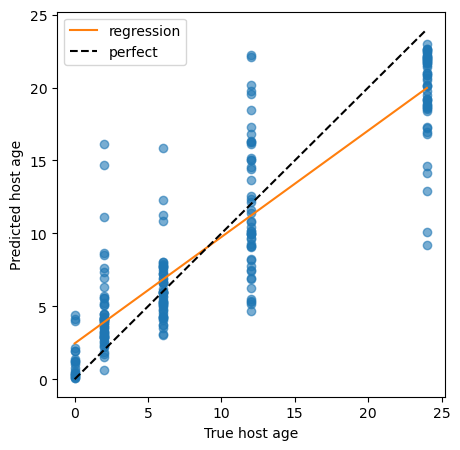

In [10]:
lr = st.linregress(y_true, y_pred)
metrics = pd.Series({
    "MAE": mean_absolute_error(y_true, y_pred),
    "MSE": mean_squared_error(y_true, y_pred),
    "r": lr.rvalue, "R2": r2_score(y_true, y_pred),
    "p-value": lr.pvalue, "SE": lr.stderr,
    "slope": lr.slope, "intercept": lr.intercept,
}, name="value").to_frame()
display(metrics)


fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_true, y_pred, alpha=0.6)
xs = np.array([y_true.min(), y_true.max()])
ax.plot(xs, lr.slope * xs + lr.intercept, color="C1", label="regression")
ax.plot(xs, xs, "k--", label="perfect")
ax.set(xlabel="True host age", ylabel="Predicted host age")
ax.legend()
plt.show()

# 2. Feature importance

In [ ]:
tax = q2.Artifact.load(f"{featuretable_dir}/../02_taxonomicclassification/taxonomy-table.qza").view(pd.DataFrame)

In [12]:
rf.fit(ft, y)
imp = pd.DataFrame({"importance": rf.feature_importances_}, index=ft.columns).join(tax["Taxon"])
top = imp.sort_values("importance", ascending=False).head(20)
top

,importance,Taxon
61592,0.578522,d__Bacteria;k__Bacillati;p__Actinomycetota;c__...
461393,0.041395,d__Bacteria;k__Bacillati;p__Actinomycetota;c__...
706438,0.031497,d__Bacteria;k__Bacillati;p__Actinomycetota;c__...
1750,0.029849,d__Bacteria;k__Bacillati;p__Actinomycetota;c__...
1655,0.017180,d__Bacteria;k__Bacillati;p__Actinomycetota;c__...
33945,0.011544,d__Bacteria;k__Bacillati;p__Bacillota;c__Bacil...
2929491,0.011090,d__Bacteria;k__Bacillati;p__Bacillota;c__Clost...
544580,0.010850,d__Bacteria;k__Bacillati;p__Actinomycetota;c__...
2929490,0.007794,d__Bacteria;k__Bacillati;p__Bacillota;c__Clost...
261299,0.006521,d__Bacteria;k__Bacillati;p__Bacillota;c__Clost...


# 3. Top features

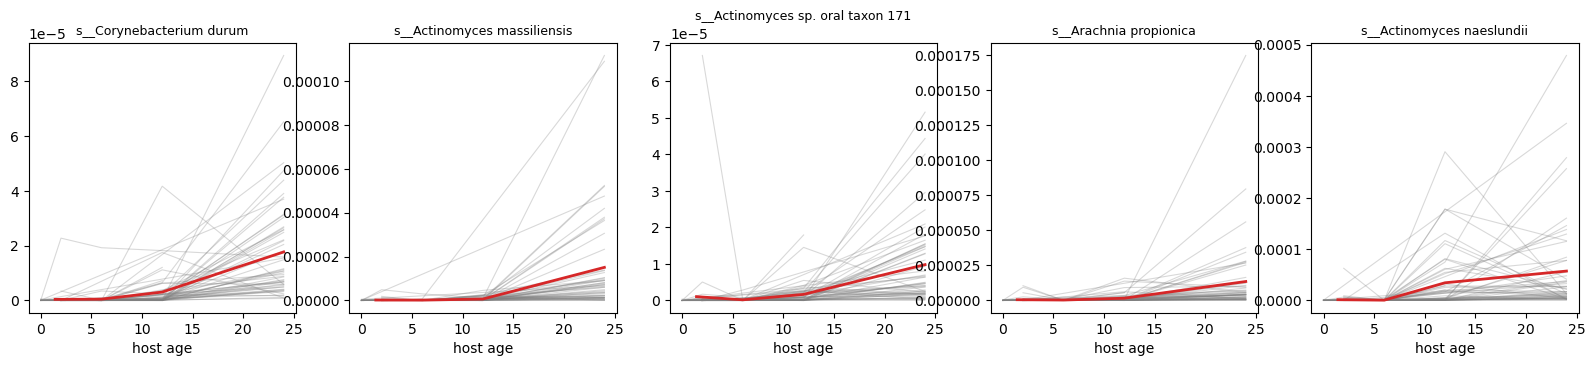

In [13]:
rel = ft.div(ft.sum(axis=1), axis=0)
top5 = top.index[:5]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharex=True)
for ax, f in zip(axes, top5):
    d = pd.DataFrame({"age": y, "abund": rel[f], "id": groups})
    for _, g in d.groupby("id"):
        ax.plot(g["age"], g["abund"], color="grey", alpha=0.3, lw=0.8)
    ax.plot(*d.groupby(pd.cut(d["age"], 8), observed=True).agg(age=("age", "mean"), abund=("abund", "mean")).values.T, color="C3", lw=2)
    ax.set_title(top.loc[f, "Taxon"].split(";")[-1].strip(), fontsize=9)
    ax.set_xlabel("host age")
plt.show()

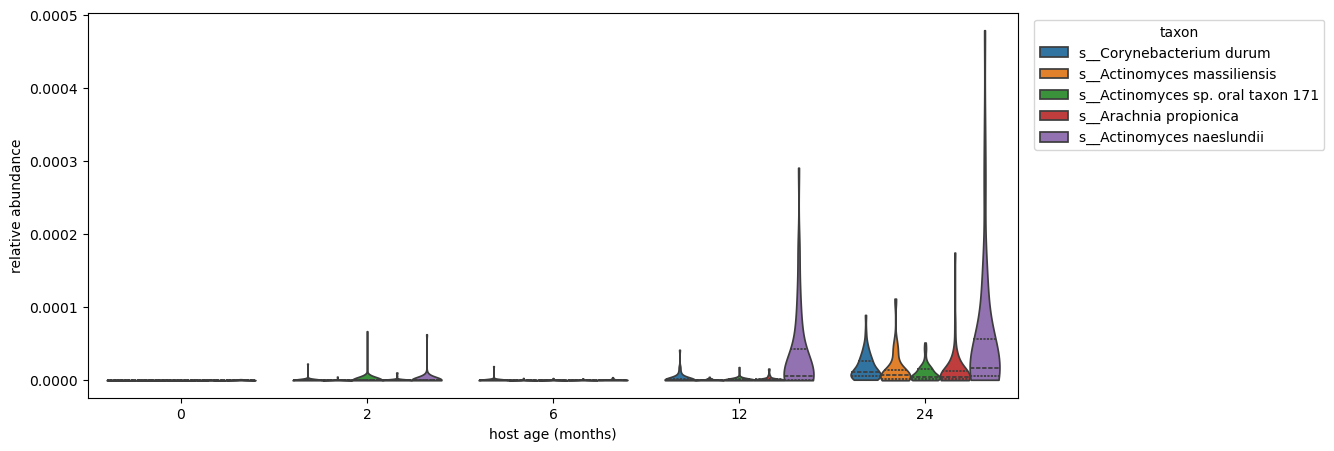

In [21]:
rel = ft.div(ft.sum(axis=1), axis=0)
top5 = top.index[:5]
labels = {f: top.loc[f, "Taxon"].split(";")[-1].strip() for f in top5}

long = (rel[top5].rename(columns=labels)
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="taxon", value_name="rel_abundance"))

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="rel_abundance", hue="taxon",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="relative abundance")
ax.legend(title="taxon", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

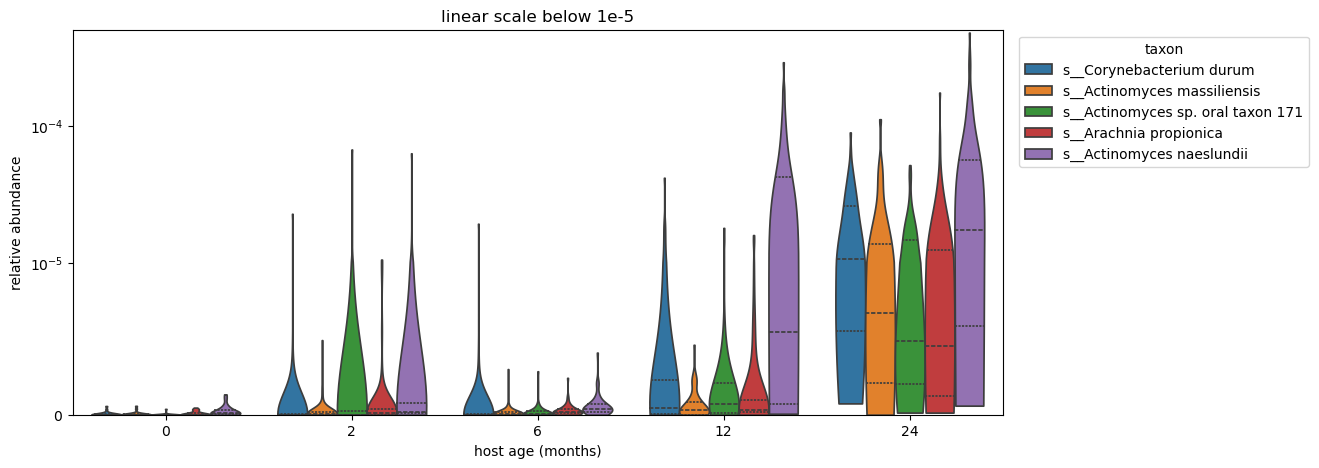

In [22]:
rel = ft.div(ft.sum(axis=1), axis=0)
top5 = top.index[:5]
labels = {f: top.loc[f, "Taxon"].split(";")[-1].strip() for f in top5}

long = (rel[top5].rename(columns=labels)
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="taxon", value_name="rel_abundance"))

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="rel_abundance", hue="taxon",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="relative abundance")
ax.legend(title="taxon", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_yscale("symlog", linthresh=1e-5)   # linear below 0.1%, log above
ax.set_ylim(bottom=0)
plt.title("linear scale below 1e-5")
plt.show()

# 4. Biologically expected top features

Bifidobacterium     234
Escherichia         234
Bacteroides         231
Faecalibacterium    218
Enterococcus        231
dtype: int64


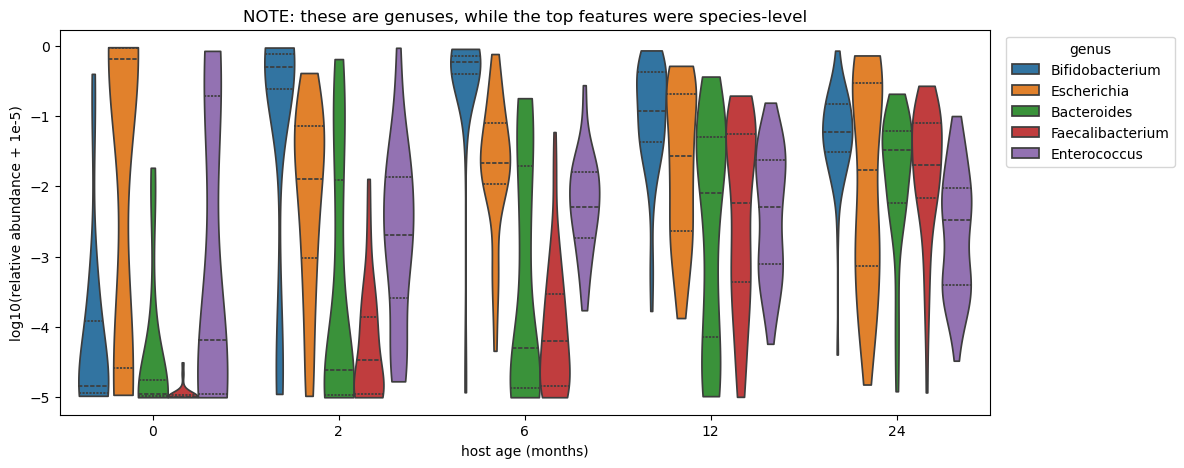

In [24]:
genera = ["Bifidobacterium", "Escherichia", "Bacteroides", "Faecalibacterium", "Enterococcus"]

# sum all features whose taxonomy contains the genus (g__ prefix avoids partial matches)
rel = ft.div(ft.sum(axis=1), axis=0)
genus_abund = pd.DataFrame({
    g: rel.loc[:, rel.columns.isin(tax.index[tax["Taxon"].str.contains(rf"g__{g}\b", na=False)])].sum(axis=1)
    for g in genera
})
print((genus_abund > 0).sum())   # sanity check: samples with the genus present (all columns should be > 0)

long = (genus_abund
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="genus", value_name="rel_abundance"))
long["log_abund"] = np.log10(long["rel_abundance"] + 1e-5)

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="log_abund", hue="genus",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="log10(relative abundance + 1e-5)")
ax.legend(title="genus", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("NOTE: these are genuses, while the top features were species-level")
plt.show()